# Learning a model-discriminative, parameter-invariant statistic

This notebook implements the proposed invariant-statistics experiment for three positive-data models:

1. Exponential with rate $\theta$;
2. Log-normal with log-location $\theta$ and log-scale standard deviation 1;
3. Gamma with shape 2 and rate $\theta$.

Each input is an unordered sample of 100 observations. A permutation-invariant DeepSets encoder learns a two-dimensional statistic $T(y)$. A model classifier encourages $T(y)$ to retain model information, while three model-specific adversaries try to recover the nuisance parameter. A gradient-reversal layer makes the encoder *increase* adversarial prediction error while the adversaries themselves continue to minimize it.

The experiment compares several adversarial strengths $\lambda$. Invariance is assessed with fresh post-hoc parameter probes and parameter-bin separation, not with the training adversary alone.

In [10]:
from pathlib import Path
import json
import os
import random

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/mpl-scdl3991")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import accuracy_score, confusion_matrix, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split

SEED = 3991
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

MODEL_NAMES = np.array(["Exponential", "Log-normal", "Gamma"])
SAMPLE_SIZE = 100
N_PER_MODEL = 3_000
N_DATASETS = 3 * N_PER_MODEL
EPOCHS = 20
BATCH_SIZE = 256
LAMBDA_VALUES = [0.0, 0.5, 2.0]

BASE_DIR = Path.cwd()
if BASE_DIR.name != "week9" and (BASE_DIR / "week9").is_dir():
    BASE_DIR = BASE_DIR / "week9"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print(f"Simulated datasets: {N_DATASETS:,}; observations per dataset: {SAMPLE_SIZE}")
print("Output directory:", OUTPUT_DIR.resolve())

TensorFlow: 2.21.0
Simulated datasets: 9,000; observations per dataset: 100
Output directory: /Users/selinalu/Desktop/scdl3991/week9/outputs


## 1. Prior-predictive simulation

For every dataset, first draw a model, then draw its parameter from the model-specific prior, and finally generate 100 i.i.d. observations. The model prior is balanced. Rates are bounded away from numerical zero only when passed to the random-number generator.

For the adversarial target we use $\eta=\log\theta$ for the two rate models and $\eta=\theta$ for the Log-normal model. These coordinates describe the additive shift induced in log-data. They are standardized separately within each model using training data only.

In [11]:
rng = np.random.default_rng(SEED)

theta_exp = rng.exponential(scale=1.0, size=N_PER_MODEL)
theta_logn = rng.normal(loc=0.0, scale=1.0, size=N_PER_MODEL)
theta_gamma = rng.exponential(scale=1.0, size=N_PER_MODEL)

exp_samples = rng.exponential(
    scale=1.0 / np.clip(theta_exp[:, None], 1e-6, None),
    size=(N_PER_MODEL, SAMPLE_SIZE),
)
logn_samples = rng.lognormal(
    mean=theta_logn[:, None], sigma=1.0,
    size=(N_PER_MODEL, SAMPLE_SIZE),
)
gamma_samples = rng.gamma(
    shape=2.0,
    scale=1.0 / np.clip(theta_gamma[:, None], 1e-6, None),
    size=(N_PER_MODEL, SAMPLE_SIZE),
)

X_raw = np.vstack([exp_samples, logn_samples, gamma_samples]).astype("float32")
y_model = np.repeat(np.arange(3), N_PER_MODEL).astype("int32")
theta = np.concatenate([theta_exp, theta_logn, theta_gamma]).astype("float32")
eta = np.concatenate([
    np.log(np.clip(theta_exp, 1e-6, None)),
    theta_logn,
    np.log(np.clip(theta_gamma, 1e-6, None)),
]).astype("float32")

indices = np.arange(N_DATASETS)
train_val_idx, test_idx = train_test_split(
    indices, test_size=0.20, random_state=SEED, stratify=y_model
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.20, random_state=SEED + 1,
    stratify=y_model[train_val_idx]
)

# Positive samples become additive scale families on the log scale.
X_log = np.log(np.clip(X_raw, 1e-12, None)).astype("float32")
input_mean = float(X_log[train_idx].mean())
input_sd = float(X_log[train_idx].std())
X = ((X_log - input_mean) / input_sd)[..., None].astype("float32")

eta_standardized = np.empty_like(eta)
eta_scaling = {}
for model_id, name in enumerate(MODEL_NAMES):
    mask = y_model[train_idx] == model_id
    values = eta[train_idx][mask]
    centre, scale = float(values.mean()), float(values.std())
    eta_scaling[name] = {"centre": centre, "scale": scale}
    all_mask = y_model == model_id
    eta_standardized[all_mask] = (eta[all_mask] - centre) / scale

print("Split sizes:", len(train_idx), len(val_idx), len(test_idx))
print("Input normalization:", {"mean": input_mean, "sd": input_sd})
pd.DataFrame(eta_scaling).T

Split sizes: 5760 1440 1800
Input normalization: {'mean': 0.3363701105117798, 'sd': 1.6476582288742065}


,centre,scale
Exponential,-0.594006,1.288174
Log-normal,0.009136,0.972457
Gamma,-0.558330,1.275154


## 2. DeepSets encoder and adversarial heads

The learned statistic is

\[
T(y)=\rho\!\left(\frac{1}{n}\sum_{i=1}^n \psi(y_i)\right)\in\mathbb{R}^2.
\]

Mean pooling makes $T(y)$ invariant to any permutation of the observations. The classifier minimizes categorical cross-entropy. Each adversary minimizes mean squared error within its own model. During backpropagation, the gradient-reversal layer multiplies the gradient entering the statistic by $-\lambda$, producing the encoder objective

\[
L_{\mathrm{encoder}}=L_{\mathrm{model}}-\lambda L_{\mathrm{adv}}.
\]

Sample weights activate only the adversary associated with the generating model.

In [12]:
@keras.utils.register_keras_serializable(package="InvariantStatistics")
class GradientReversal(layers.Layer):
    def __init__(self, strength=1.0, **kwargs):
        super().__init__(**kwargs)
        self.strength = float(strength)

    def call(self, inputs):
        strength = tf.cast(self.strength, inputs.dtype)

        @tf.custom_gradient
        def reverse(x):
            def grad(upstream):
                return -strength * upstream
            return tf.identity(x), grad

        return reverse(inputs)

    def get_config(self):
        config = super().get_config()
        config.update({"strength": self.strength})
        return config


def build_invariant_model(adversarial_strength):
    inputs = keras.Input(shape=(SAMPLE_SIZE, 1), name="dataset")

    # The same pointwise network psi is applied to every observation.
    x = layers.Dense(32, activation="elu", name="pointwise_1")(inputs)
    x = layers.Dense(32, activation="elu", name="pointwise_2")(x)
    pooled = layers.GlobalAveragePooling1D(name="symmetric_mean_pool")(x)
    x = layers.Dense(32, activation="elu", name="rho")(pooled)
    statistic = layers.Dense(2, name="statistic")(x)

    class_hidden = layers.Dense(24, activation="elu", name="class_hidden")(statistic)
    class_output = layers.Dense(3, activation="softmax", name="class_output")(class_hidden)

    reversed_statistic = GradientReversal(
        adversarial_strength, name="gradient_reversal"
    )(statistic)
    outputs = {"class_output": class_output}
    for model_id, short_name in enumerate(["exp", "logn", "gamma"]):
        h = layers.Dense(64, activation="elu", name=f"{short_name}_adv_hidden_1")(
            reversed_statistic
        )
        h = layers.Dense(64, activation="elu", name=f"{short_name}_adv_hidden_2")(h)
        outputs[f"{short_name}_adv"] = layers.Dense(
            1, name=f"{short_name}_adv"
        )(h)

    model = keras.Model(inputs, outputs, name=f"invariant_deepsets_lambda_{adversarial_strength}")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss={
            "class_output": "sparse_categorical_crossentropy",
            "exp_adv": "mse",
            "logn_adv": "mse",
            "gamma_adv": "mse",
        },
        metrics={"class_output": ["accuracy"]},
    )
    return model


def targets_and_weights(idx):
    target = eta_standardized[idx, None]
    labels = y_model[idx]
    targets = {
        "class_output": labels,
        "exp_adv": target,
        "logn_adv": target,
        "gamma_adv": target,
    }
    weights = {
        "class_output": np.ones(len(idx), dtype="float32"),
        "exp_adv": (labels == 0).astype("float32"),
        "logn_adv": (labels == 1).astype("float32"),
        "gamma_adv": (labels == 2).astype("float32"),
    }
    return targets, weights


train_targets, train_weights = targets_and_weights(train_idx)
val_targets, val_weights = targets_and_weights(val_idx)

preview = build_invariant_model(1.0)
preview.summary()

Model: "invariant_deepsets_lambda_1.0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ dataset             │ (None, 100, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pointwise_1 (Dense) │ (None, 100, 32)   │         64 │ dataset[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pointwise_2 (Dense) │ (None, 100, 32)   │      1,056 │ pointwise_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ symmetric_mean_pool │ (None, 32)        │          0 │ pointwise_2[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rho (Dense)         │ (None, 32)        │      1,056 │ symmetric_mean_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ statistic (Dense)   │ (None, 2)         │         66 │ rho[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gradient_reversal   │ (None, 2)         │          0 │ statistic[0][0]   │
│ (GradientReversal)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ exp_adv_hidden_1    │ (None, 64)        │        192 │ gradient_reversa… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gamma_adv_hidden_1  │ (None, 64)        │        192 │ gradient_reversa… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logn_adv_hidden_1   │ (None, 64)        │        192 │ gradient_reversa… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_hidden        │ (None, 24)        │         72 │ statistic[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ exp_adv_hidden_2    │ (None, 64)        │      4,160 │ exp_adv_hidden_1… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gamma_adv_hidden_2  │ (None, 64)        │      4,160 │ gamma_adv_hidden… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logn_adv_hidden_2   │ (None, 64)        │      4,160 │ logn_adv_hidden_… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 3)         │         75 │ class_hidden[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ exp_adv (Dense)     │ (None, 1)         │         65 │ exp_adv_hidden_2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gamma_adv (Dense)   │ (None, 1)         │         65 │ gamma_adv_hidden… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logn_adv (Dense)    │ (None, 1)         │         65 │ logn_adv_hidden_… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 15,640 (61.09 KB)

 Trainable params: 15,640 (61.09 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Train a baseline and adversarial models

$\lambda=0$ is the classifier baseline: the adversaries learn to read the statistic but cannot change the encoder. Positive values of $\lambda$ make the encoder resist parameter prediction. Every setting uses the same data split and architecture.

In [13]:
models_by_lambda = {}
histories_by_lambda = {}

baseline_weights = None
for lam in LAMBDA_VALUES:
    print(f"\n--- Training lambda={lam:g} ---")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_invariant_model(lam)
    if baseline_weights is not None:
        # Begin adversarial fine-tuning from a representation for which both the
        # classifier and parameter readers are already trained.
        model.set_weights(baseline_weights)
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_class_output_accuracy",
            mode="max", patience=4, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_class_output_accuracy",
            mode="max", factor=0.5, patience=2, min_lr=1e-5
        ),
    ]
    history = model.fit(
        X[train_idx], train_targets,
        sample_weight=train_weights,
        validation_data=(X[val_idx], val_targets, val_weights),
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        callbacks=callbacks, verbose=2,
    )
    models_by_lambda[lam] = model
    histories_by_lambda[lam] = history.history
    if lam == 0.0:
        baseline_weights = model.get_weights()

print("Finished training", len(models_by_lambda), "models.")


--- Training lambda=0 ---
Epoch 1/20
23/23 - 2s - 67ms/step - class_output_accuracy: 0.4380 - class_output_loss: 1.0474 - exp_adv_loss: 0.1643 - gamma_adv_loss: 0.1526 - logn_adv_loss: 0.1440 - loss: 1.5155 - val_class_output_accuracy: 0.4493 - val_class_output_loss: 1.0211 - val_exp_adv_loss: 0.0560 - val_gamma_adv_loss: 0.0655 - val_logn_adv_loss: 0.0582 - val_loss: 1.1995 - learning_rate: 0.0010
Epoch 2/20
23/23 - 0s - 4ms/step - class_output_accuracy: 0.4720 - class_output_loss: 1.0236 - exp_adv_loss: 0.0277 - gamma_adv_loss: 0.0344 - logn_adv_loss: 0.0213 - loss: 1.1085 - val_class_output_accuracy: 0.4847 - val_class_output_loss: 1.0198 - val_exp_adv_loss: 0.0136 - val_gamma_adv_loss: 0.0196 - val_logn_adv_loss: 0.0092 - val_loss: 1.0608 - learning_rate: 0.0010
Epoch 3/20
23/23 - 0s - 4ms/step - class_output_accuracy: 0.4601 - class_output_loss: 1.0167 - exp_adv_loss: 0.0145 - gamma_adv_loss: 0.0223 - logn_adv_loss: 0.0089 - loss: 1.0632 - val_class_output_accuracy: 0.4840 - val_

## 4. Independent evaluation of model information and parameter leakage

An unsuccessful training adversary does not by itself prove invariance. Therefore, after freezing each encoder, a fresh nonlinear Extra Trees probe is fitted separately within each model to predict the standardized parameter from $T(y)$. Lower test-set probe $R^2$ indicates less recoverable parameter information.

We also divide the test parameters into four within-model quantile bins. The parameter-bin separation is the fraction of statistic variation explained by differences between the four bin centroids. Lower separation means that the statistic distribution is more stable as the parameter changes.

In [14]:
def bin_separation(statistic, parameter, n_bins=4):
    edges = np.unique(np.quantile(parameter, np.linspace(0, 1, n_bins + 1)))
    bins = np.digitize(parameter, edges[1:-1], right=True)
    overall = statistic.mean(axis=0)
    total = np.sum((statistic - overall) ** 2)
    between = 0.0
    for b in np.unique(bins):
        group = statistic[bins == b]
        between += len(group) * np.sum((group.mean(axis=0) - overall) ** 2)
    return float(between / max(total, 1e-12))


metric_rows = []
probe_rows = []
statistics_by_lambda = {}
predictions_by_lambda = {}

for lam, model in models_by_lambda.items():
    predicted = model.predict(X[test_idx], batch_size=BATCH_SIZE, verbose=0)
    model_prediction = predicted["class_output"].argmax(axis=1)
    test_accuracy = accuracy_score(y_model[test_idx], model_prediction)

    statistic_model = keras.Model(model.input, model.get_layer("statistic").output)
    train_stat = statistic_model.predict(X[train_idx], batch_size=BATCH_SIZE, verbose=0)
    test_stat = statistic_model.predict(X[test_idx], batch_size=BATCH_SIZE, verbose=0)
    statistics_by_lambda[lam] = {"train": train_stat, "test": test_stat}
    predictions_by_lambda[lam] = model_prediction

    model_probe_r2 = []
    model_probe_mae = []
    model_separation = []
    for model_id, name in enumerate(MODEL_NAMES):
        train_mask = y_model[train_idx] == model_id
        test_mask = y_model[test_idx] == model_id
        probe = ExtraTreesRegressor(
            n_estimators=250, min_samples_leaf=8,
            random_state=SEED, n_jobs=-1
        )
        probe.fit(train_stat[train_mask], eta_standardized[train_idx][train_mask])
        probe_prediction = probe.predict(test_stat[test_mask])
        probe_r2 = r2_score(eta_standardized[test_idx][test_mask], probe_prediction)
        probe_mae = mean_absolute_error(
            eta_standardized[test_idx][test_mask], probe_prediction
        )
        separation = bin_separation(
            test_stat[test_mask], eta_standardized[test_idx][test_mask]
        )
        model_probe_r2.append(probe_r2)
        model_probe_mae.append(probe_mae)
        model_separation.append(separation)
        probe_rows.append({
            "lambda": lam,
            "model": name,
            "probe_r2": probe_r2,
            "probe_mae": probe_mae,
            "parameter_bin_separation": separation,
        })

    metric_rows.append({
        "lambda": lam,
        "classification_accuracy": test_accuracy,
        "mean_probe_r2": float(np.mean(model_probe_r2)),
        "mean_probe_mae": float(np.mean(model_probe_mae)),
        "mean_parameter_bin_separation": float(np.mean(model_separation)),
    })

metrics = pd.DataFrame(metric_rows).sort_values("lambda").reset_index(drop=True)
probe_metrics = pd.DataFrame(probe_rows)
metrics.to_csv(OUTPUT_DIR / "invariant_statistics_metrics.csv", index=False)
probe_metrics.to_csv(OUTPUT_DIR / "invariant_statistics_probe_by_model.csv", index=False)
print(metrics.to_string(index=False))
probe_metrics

 lambda  classification_accuracy  mean_probe_r2  mean_probe_mae  mean_parameter_bin_separation
    0.0                 0.787222       0.981375        0.094280                       0.698142
    0.5                 0.825000       0.509099        0.523087                       0.548444
    2.0                 0.717222       0.985088        0.078164                       0.829083


,lambda,model,probe_r2,probe_mae,parameter_bin_separation
0,0.0,Exponential,0.978515,0.109154,0.638324
1,0.0,Log-normal,0.972282,0.118684,0.645209
2,0.0,Gamma,0.993329,0.055001,0.810894
3,0.5,Exponential,0.227173,0.679711,0.414579
4,0.5,Log-normal,0.552439,0.547421,0.561357
5,0.5,Gamma,0.747684,0.342128,0.669397
6,2.0,Exponential,0.979293,0.083635,0.856242
7,2.0,Log-normal,0.983082,0.095373,0.811635
8,2.0,Gamma,0.992890,0.055484,0.819374


## 5. Visual results

The first figure shows the accuracy-invariance trade-off. The selected adversarial setting is the positive $\lambda$ with the lowest post-hoc probe $R^2$. The second compares confusion matrices for the non-adversarial and selected settings. The third colours the two-dimensional learned statistic by the nuisance parameter within each model; reduced colour gradients are visual evidence of increased invariance.

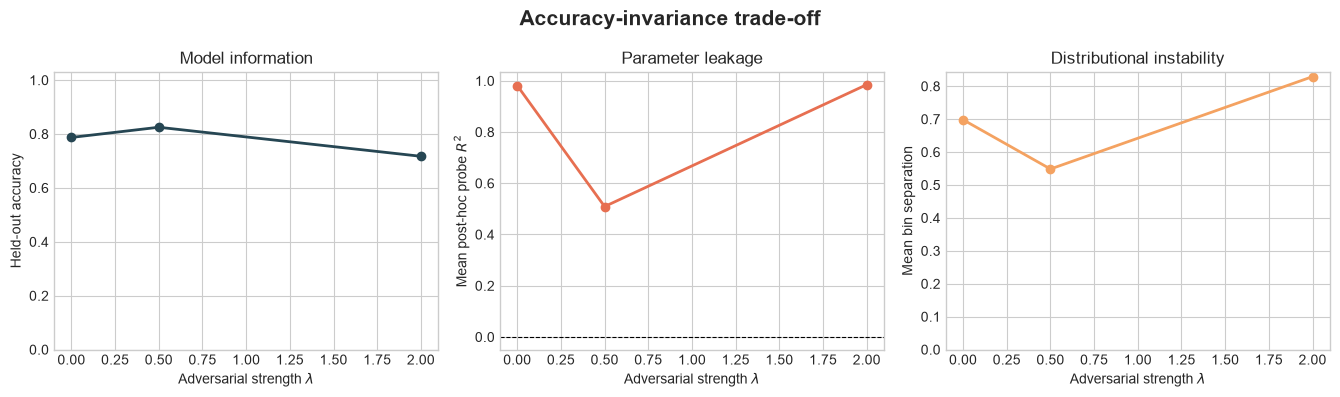

Selected adversarial setting: lambda=0.5


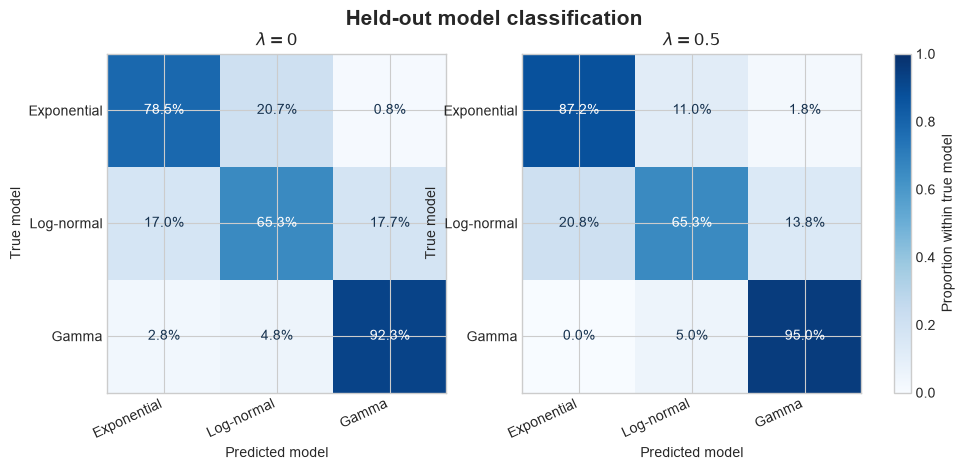

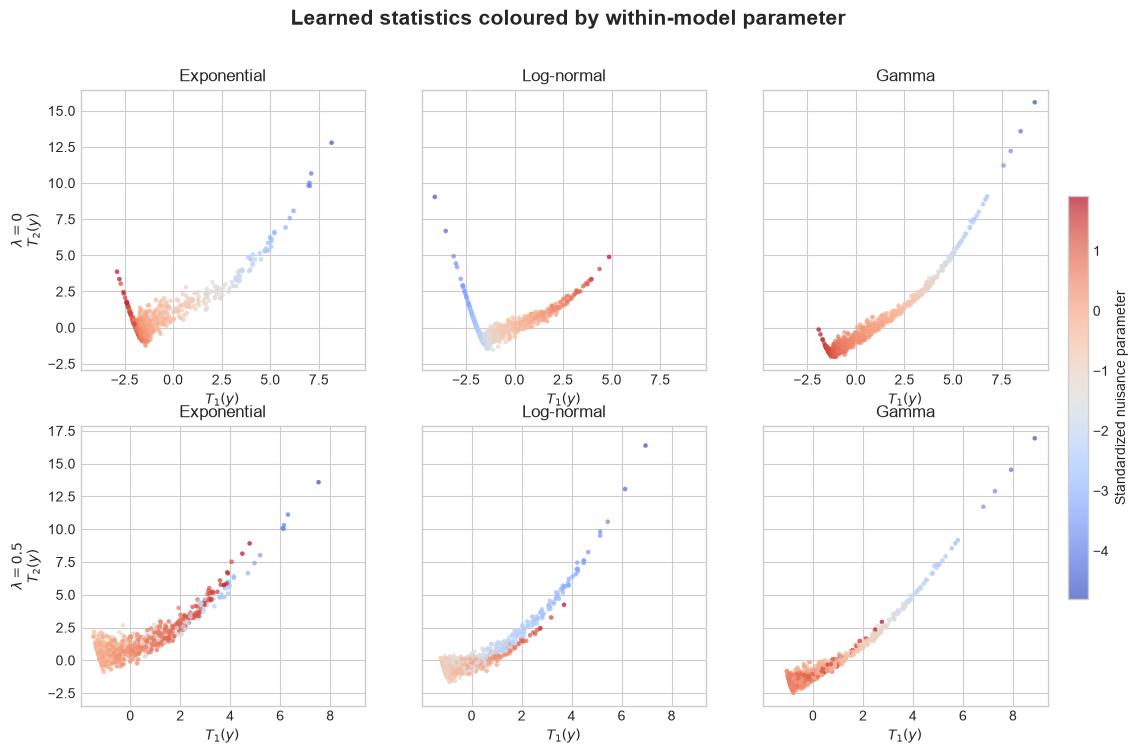

Saved figures:
 - /Users/selinalu/Desktop/scdl3991/week9/outputs/accuracy_invariance_tradeoff.png
 - /Users/selinalu/Desktop/scdl3991/week9/outputs/invariant_confusion_matrices.png
 - /Users/selinalu/Desktop/scdl3991/week9/outputs/learned_invariant_statistics.png


In [15]:
plt.style.use("seaborn-v0_8-whitegrid")
colour = "#2A9D8F"

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
axes[0].plot(metrics["lambda"], metrics["classification_accuracy"], "o-", color="#264653", lw=2)
axes[0].set(ylabel="Held-out accuracy", xlabel=r"Adversarial strength $\lambda$", ylim=(0, 1.03))
axes[0].set_title("Model information")
axes[1].plot(metrics["lambda"], metrics["mean_probe_r2"], "o-", color="#E76F51", lw=2)
axes[1].axhline(0, color="black", lw=0.8, ls="--")
axes[1].set(ylabel=r"Mean post-hoc probe $R^2$", xlabel=r"Adversarial strength $\lambda$")
axes[1].set_title("Parameter leakage")
axes[2].plot(metrics["lambda"], metrics["mean_parameter_bin_separation"], "o-", color="#F4A261", lw=2)
axes[2].set(ylabel="Mean bin separation", xlabel=r"Adversarial strength $\lambda$", ylim=(0, None))
axes[2].set_title("Distributional instability")
fig.suptitle("Accuracy-invariance trade-off", fontsize=15, weight="bold")
fig.tight_layout()
tradeoff_path = OUTPUT_DIR / "accuracy_invariance_tradeoff.png"
fig.savefig(tradeoff_path, dpi=300, bbox_inches="tight")
plt.show()

baseline_lambda = LAMBDA_VALUES[0]
positive_metrics = metrics.loc[metrics["lambda"] > 0]
adversarial_lambda = float(
    positive_metrics.loc[positive_metrics["mean_probe_r2"].idxmin(), "lambda"]
)
print(f"Selected adversarial setting: lambda={adversarial_lambda:g}")
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
for ax, lam in zip(axes, [baseline_lambda, adversarial_lambda]):
    cm = confusion_matrix(
        y_model[test_idx], predictions_by_lambda[lam], labels=[0, 1, 2], normalize="true"
    )
    image = ax.imshow(cm, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(3), MODEL_NAMES, rotation=25, ha="right")
    ax.set_yticks(range(3), MODEL_NAMES)
    ax.set(xlabel="Predicted model", ylabel="True model", title=fr"$\lambda={lam:g}$")
    for row in range(3):
        for col in range(3):
            ax.text(col, row, f"{cm[row, col]:.1%}", ha="center", va="center",
                    color="white" if cm[row, col] > 0.5 else "#16324F")
fig.colorbar(image, ax=axes, fraction=0.025, pad=0.04, label="Proportion within true model")
fig.suptitle("Held-out model classification", fontsize=15, weight="bold")
confusion_path = OUTPUT_DIR / "invariant_confusion_matrices.png"
fig.savefig(confusion_path, dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex="row", sharey="row")
last_scatter = None
for row, lam in enumerate([baseline_lambda, adversarial_lambda]):
    statistic = statistics_by_lambda[lam]["test"]
    for model_id, name in enumerate(MODEL_NAMES):
        mask = y_model[test_idx] == model_id
        last_scatter = axes[row, model_id].scatter(
            statistic[mask, 0], statistic[mask, 1],
            c=eta_standardized[test_idx][mask], cmap="coolwarm",
            s=11, alpha=0.70, linewidths=0
        )
        axes[row, model_id].set_title(name)
        axes[row, model_id].set_xlabel(r"$T_1(y)$")
        if model_id == 0:
            axes[row, model_id].set_ylabel(fr"$\lambda={lam:g}$" + "\n" + r"$T_2(y)$")
fig.colorbar(last_scatter, ax=axes, fraction=0.020, pad=0.02,
             label="Standardized nuisance parameter")
fig.suptitle("Learned statistics coloured by within-model parameter", fontsize=15, weight="bold")
statistic_path = OUTPUT_DIR / "learned_invariant_statistics.png"
fig.savefig(statistic_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figures:")
for path in [tradeoff_path, confusion_path, statistic_path]:
    print(" -", path)

## 6. Permutation-invariance check

The observations are i.i.d., so their ordering must not change the learned statistic. The following numerical assertion permutes every observation vector independently and checks that the DeepSets output is unchanged to floating-point tolerance.

In [16]:
check_rng = np.random.default_rng(SEED + 100)
check_rows = test_idx[:128]
permuted = np.stack([check_rng.permutation(row[:, 0]) for row in X[check_rows]])[..., None]
positive_metrics = metrics.loc[metrics["lambda"] > 0]
selected_lambda = float(
    positive_metrics.loc[positive_metrics["mean_probe_r2"].idxmin(), "lambda"]
)
selected_model = models_by_lambda[selected_lambda]
selected_statistic_model = keras.Model(
    selected_model.input, selected_model.get_layer("statistic").output
)
original_stat = selected_statistic_model.predict(X[check_rows], verbose=0)
permuted_stat = selected_statistic_model.predict(permuted, verbose=0)
max_permutation_difference = float(np.max(np.abs(original_stat - permuted_stat)))
print("Maximum statistic change after permutation:", max_permutation_difference)
assert max_permutation_difference < 1e-5

# Save the selected adversarial weights and run metadata.
selected_model.save_weights(OUTPUT_DIR / "invariant_deepsets_selected.weights.h5")
run_metadata = {
    "seed": SEED,
    "n_datasets": N_DATASETS,
    "sample_size": SAMPLE_SIZE,
    "epochs_max": EPOCHS,
    "batch_size": BATCH_SIZE,
    "lambda_values": LAMBDA_VALUES,
    "selected_lambda": selected_lambda,
    "input_mean": input_mean,
    "input_sd": input_sd,
    "eta_scaling": eta_scaling,
    "max_permutation_difference": max_permutation_difference,
}
with open(OUTPUT_DIR / "run_metadata.json", "w") as stream:
    json.dump(run_metadata, stream, indent=2)
print("Saved weights and run metadata.")

Maximum statistic change after permutation: 9.5367431640625e-07
Saved weights and run metadata.


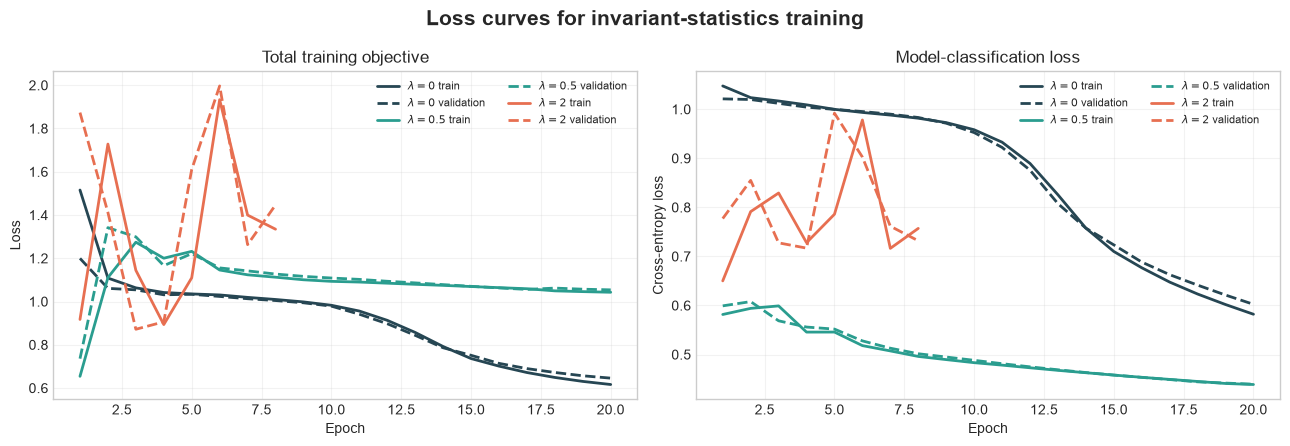

Saved: /Users/selinalu/Desktop/scdl3991/week9/outputs/invariant_training_loss_curves.png


In [17]:
# Training-loss curves for the baseline and adversarial models
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colours = {0.0: "#264653", 0.5: "#2A9D8F", 2.0: "#E76F51"}

for lam in sorted(histories_by_lambda):
    history = histories_by_lambda[lam]
    epochs = range(1, len(history["loss"]) + 1)
    colour = colours.get(lam, None)

    axes[0].plot(epochs, history["loss"], color=colour, lw=2,
                 label=fr"$\lambda={lam:g}$ train")
    axes[0].plot(epochs, history["val_loss"], color=colour, lw=2, ls="--",
                 label=fr"$\lambda={lam:g}$ validation")

    axes[1].plot(epochs, history["class_output_loss"], color=colour, lw=2,
                 label=fr"$\lambda={lam:g}$ train")
    axes[1].plot(epochs, history["val_class_output_loss"], color=colour, lw=2, ls="--",
                 label=fr"$\lambda={lam:g}$ validation")

axes[0].set(title="Total training objective", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Model-classification loss", xlabel="Epoch", ylabel="Cross-entropy loss")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, ncol=2)

fig.suptitle("Loss curves for invariant-statistics training", fontsize=15, weight="bold")
fig.tight_layout()
loss_plot_path = OUTPUT_DIR / "invariant_training_loss_curves.png"
fig.savefig(loss_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", loss_plot_path)
